# PC3 · Modelo de difusión para generar rostros de anime

**Script de obtención de resultados.** Carga los pesos EMA obtenidos en `01_entrenamiento.ipynb` y genera rostros nuevos a partir de ruido.

Además de generar desde ruido, la sección 9 lleva rostros reales a otra época y la sección 10 muestra el ajuste hecho al muestreo DDIM.

In [1]:
import os, time, json
import numpy as np
import torch
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from modelo import UNet, Difusion, EPOCAS

dev = "cuda"
os.makedirs("resultados", exist_ok=True)
red = UNet(ch=64, attn_res=(8,)).to(dev).eval()
red.load_state_dict(torch.load("pesos/pesos_ema.pt", weights_only=True))
dif = Difusion(1000, 1e-4, 0.02, dev)
log = json.load(open("pesos/log_entrenamiento.json"))
print(f"Pesos: pesos/pesos_ema.pt ({os.path.getsize('pesos/pesos_ema.pt') / 1e6:.1f} MB)")
print(f"Entrenados {len(log)} épocas en {sum(r['segundos'] for r in log) / 3600:.2f} h | pérdida final {log[-1]['perdida']:.4f}")

def a_img(x):
    return ((x.float().clamp(-1, 1) + 1) / 2).cpu().permute(0, 2, 3, 1).numpy()

def grilla(imgs, cols):
    filas = [np.hstack(list(imgs[i:i + cols])) for i in range(0, len(imgs), cols)]
    return np.vstack(filas)

def generar(z, e, metodo="ddim", guia=2.0, **kw):
    with torch.autocast("cuda", dtype=torch.bfloat16):
        f = dif.ddim if metodo == "ddim" else dif.ddpm
        return f(red, z, e, guia=guia, **kw)

Pesos: pesos/pesos_ema.pt (72.9 MB)
Entrenados 50 épocas en 4.71 h | pérdida final 0.0269


## 1. Rostros generados frente a rostros reales

64 rostros en 12.3 s (DDIM, 50 pasos)


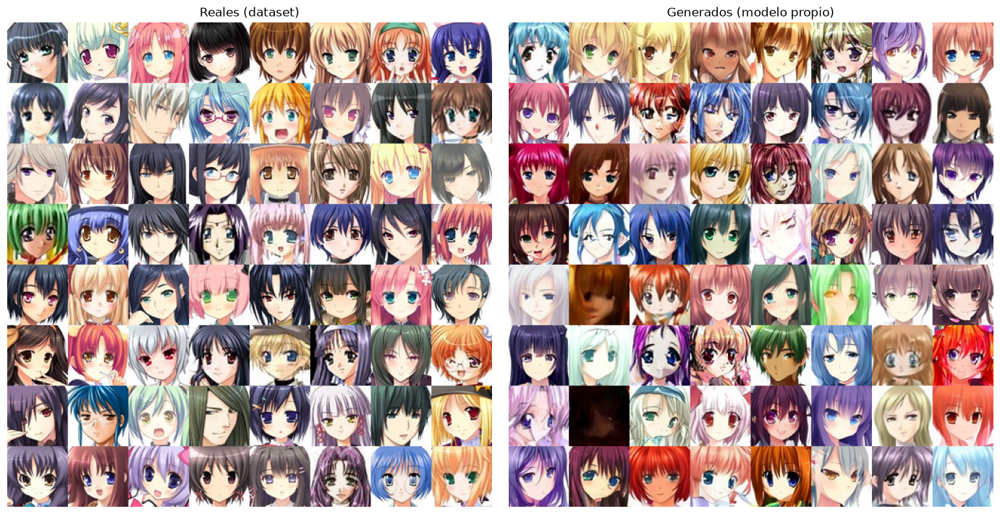

In [2]:
torch.manual_seed(7)
z = torch.randn(64, 3, 64, 64, device=dev)
e = torch.randint(0, 4, (64,), device=dev)
t0 = time.time()
gen, _ = generar(z, e)
print(f"64 rostros en {time.time() - t0:.1f} s (DDIM, 50 pasos)")

d = np.load("datos/anime64.npz")
reales = d["imgs"][np.random.default_rng(7).choice(len(d["imgs"]), 64, replace=False)] / 255
fig, ax = plt.subplots(1, 2, figsize=(14, 7))
ax[0].imshow(grilla(reales, 8)); ax[0].set_title("Reales (dataset)")
ax[1].imshow(grilla(a_img(gen), 8)); ax[1].set_title("Generados (modelo propio)")
for a in ax: a.axis("off")
plt.tight_layout(); plt.savefig("resultados/reales_vs_generados.png", dpi=110); plt.show()

## 2. DDPM (1000 pasos) frente a DDIM (50 pasos)

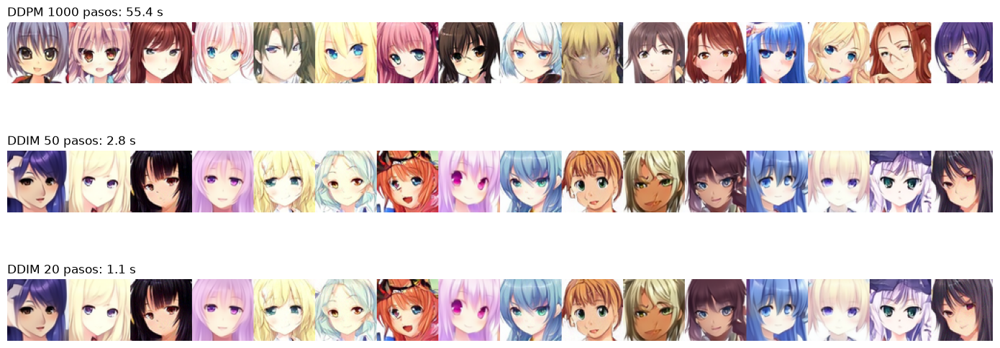

DDPM 1000 pasos: 55.4 s (3.46 s por imagen)
DDIM 50 pasos: 2.8 s (0.18 s por imagen)
DDIM 20 pasos: 1.1 s (0.07 s por imagen)


In [3]:
torch.manual_seed(3)
z = torch.randn(16, 3, 64, 64, device=dev)
e = torch.full((16,), 3, device=dev)
tiempos = {}
salidas = {}
for nombre, metodo, kw in [("DDPM 1000 pasos", "ddpm", {}), ("DDIM 50 pasos", "ddim", {"n": 50}), ("DDIM 20 pasos", "ddim", {"n": 20})]:
    torch.cuda.synchronize(); t0 = time.time()
    salidas[nombre], _ = generar(z, e, metodo, **kw)
    torch.cuda.synchronize(); tiempos[nombre] = time.time() - t0
fig, ax = plt.subplots(3, 1, figsize=(14, 6))
for a, (nombre, x) in zip(ax, salidas.items()):
    a.imshow(grilla(a_img(x), 16)); a.axis("off"); a.set_title(f"{nombre}: {tiempos[nombre]:.1f} s", loc="left")
plt.tight_layout(); plt.savefig("resultados/ddpm_vs_ddim.png", dpi=110); plt.show()
for k, v in tiempos.items():
    print(f"{k}: {v:.1f} s ({v / 16:.2f} s por imagen)")

## 3. Misma semilla, distinta época

El ruido inicial es el mismo en cada fila; solo cambia la condición de época.

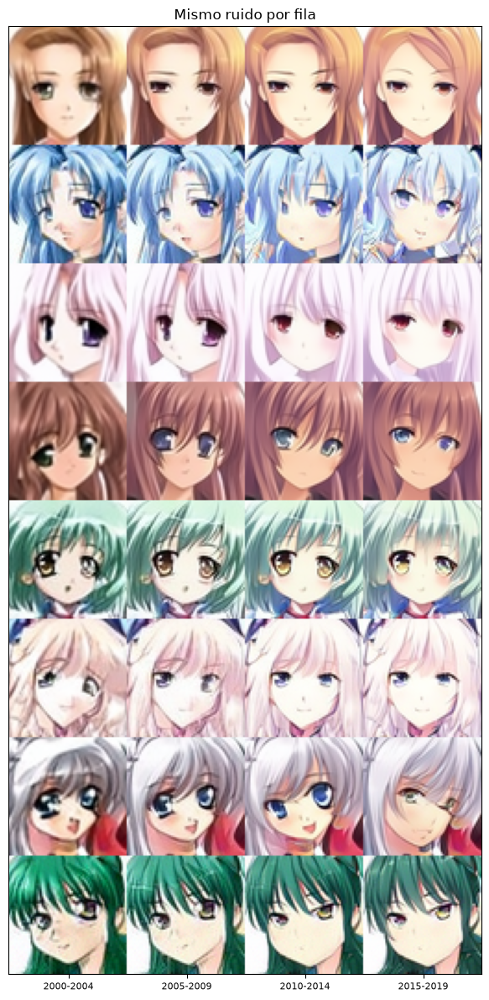

In [4]:
torch.manual_seed(11)
n = 8
z = torch.randn(n, 3, 64, 64, device=dev).repeat(4, 1, 1, 1)
e = torch.arange(4, device=dev).repeat_interleave(n)
x, _ = generar(z, e, guia=3.0)
m = a_img(x).reshape(4, n, 64, 64, 3).transpose(1, 0, 2, 3, 4).reshape(4 * n, 64, 64, 3)
fig = plt.figure(figsize=(6, 12))
plt.imshow(grilla(m, 4))
plt.xticks([32 + 64 * k for k in range(4)], EPOCAS, fontsize=8); plt.yticks([])
plt.title("Mismo ruido por fila")
plt.tight_layout(); plt.savefig("resultados/misma_semilla_por_epoca.png", dpi=120); plt.show()

## 4. ¿El modelo aprendió las épocas?

Saturación y brillo medios (HSV) de 512 rostros reales y 512 generados por época.

época       sat real  sat gen  brillo real  brillo gen
2000-2004      0.310    0.382        0.691       0.664
2005-2009      0.288    0.336        0.709       0.697
2010-2014      0.279    0.322        0.713       0.702
2015-2019      0.276    0.323        0.727       0.719


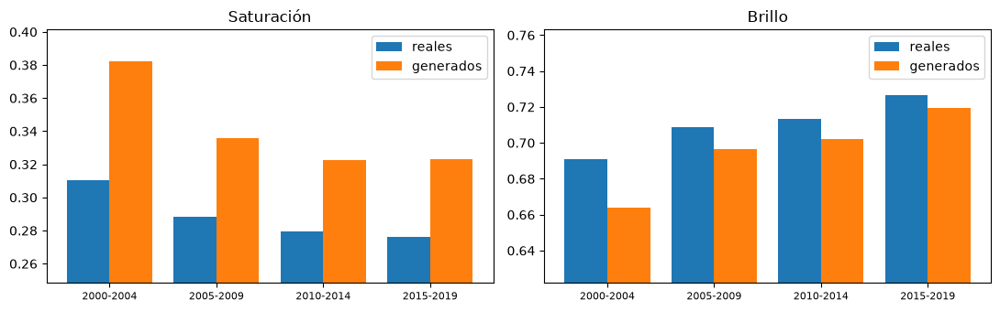

In [5]:
import matplotlib.colors as mc
def sat_val(imgs):
    hsv = mc.rgb_to_hsv(imgs.reshape(-1, 64, 64, 3).clip(0, 1))
    return hsv[..., 1].mean(), hsv[..., 2].mean()
E = (d["años"].astype(int) - 2000) // 5
filas = []
for k, nombre in enumerate(EPOCAS):
    idx = np.random.default_rng(k).choice(np.where(E == k)[0], 512, replace=False)
    sr, vr = sat_val(d["imgs"][idx] / 255)
    gens = []
    for b in range(4):
        torch.manual_seed(100 + 10 * k + b)
        x, _ = generar(torch.randn(128, 3, 64, 64, device=dev), torch.full((128,), k, device=dev), n=25)
        gens.append(a_img(x))
    sg, vg = sat_val(np.concatenate(gens))
    filas.append((nombre, sr, sg, vr, vg))
print(f"{'época':10s} {'sat real':>9s} {'sat gen':>8s} {'brillo real':>12s} {'brillo gen':>11s}")
for f in filas:
    print(f"{f[0]:10s} {f[1]:9.3f} {f[2]:8.3f} {f[3]:12.3f} {f[4]:11.3f}")
x = np.arange(4)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, (j, nom) in zip(ax, [(1, "Saturación"), (3, "Brillo")]):
    a.bar(x - 0.2, [f[j] for f in filas], 0.4, label="reales")
    a.bar(x + 0.2, [f[j + 1] for f in filas], 0.4, label="generados")
    a.set_xticks(x, EPOCAS, fontsize=8); a.set_title(nom); a.legend()
    a.set_ylim(min(f[j] for f in filas) * 0.9, max(max(f[j], f[j + 1]) for f in filas) * 1.05)
plt.tight_layout(); plt.savefig("resultados/epocas_color.png", dpi=110); plt.show()

## 5. Guía sin clasificador: fidelidad frente a diversidad

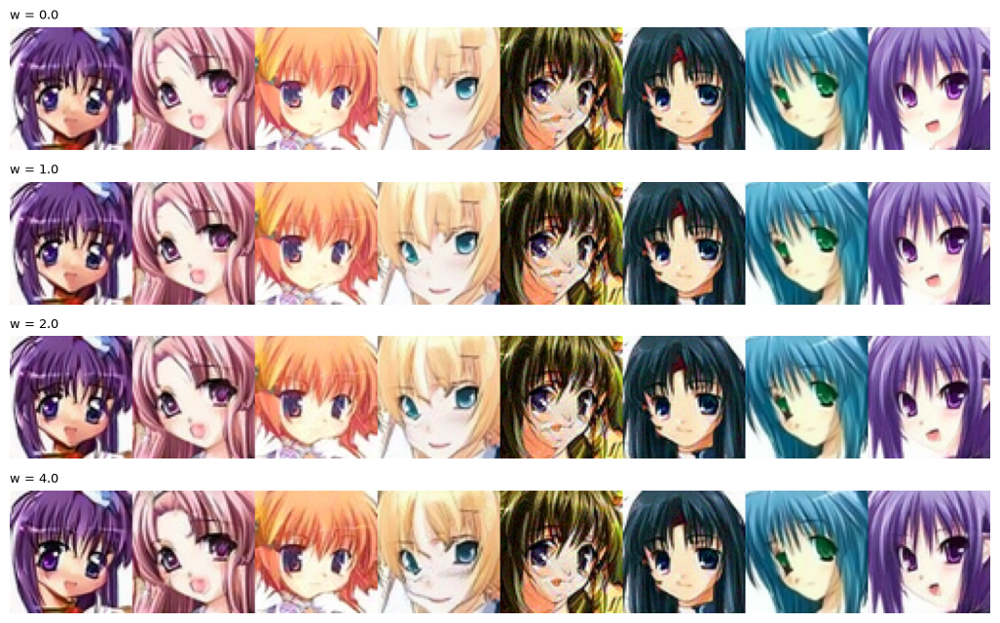

In [6]:
torch.manual_seed(5)
z = torch.randn(8, 3, 64, 64, device=dev)
e = torch.full((8,), 1, device=dev)
fig, ax = plt.subplots(4, 1, figsize=(12, 6.5))
for a, w in zip(ax, [0.0, 1.0, 2.0, 4.0]):
    x, _ = generar(z, e, guia=w)
    a.imshow(grilla(a_img(x), 8)); a.axis("off"); a.set_title(f"w = {w}", loc="left", fontsize=9)
plt.tight_layout(); plt.savefig("resultados/guia.png", dpi=110); plt.show()

## 6. Proceso inverso: de ruido a rostro (DDPM, 1000 pasos)

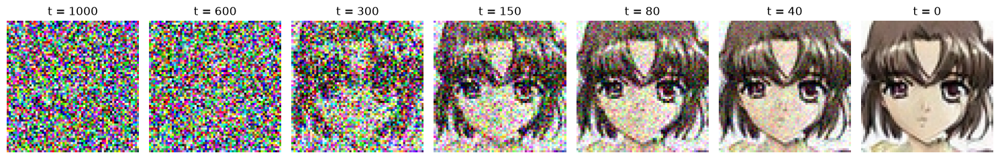

GIF: 101 cuadros


In [7]:
torch.manual_seed(21)
z = torch.randn(16, 3, 64, 64, device=dev)
e = torch.arange(4, device=dev).repeat(4)
x, pasos = generar(z, e, "ddpm", cada=10)
cuadros = [(grilla(a_img(p), 4) * 255).astype(np.uint8) for p in [z.cpu()] + pasos]
cuadros = [np.kron(c, np.ones((2, 2, 1), dtype=np.uint8)) for c in cuadros]
imageio.mimsave("resultados/proceso_inverso.gif", cuadros + [cuadros[-1]] * 15, duration=0.06, loop=0)
ver = [0, 40, 70, 85, 92, 96, 100]
fig, ax = plt.subplots(1, len(ver), figsize=(15, 2.6))
for a, i in zip(ax, ver):
    a.imshow(cuadros[i][:128, :128]); a.axis("off"); a.set_title(f"t = {1000 - 10 * i}")
plt.tight_layout(); plt.savefig("resultados/proceso_inverso.png", dpi=110); plt.show()
print("GIF:", len(cuadros), "cuadros")

## 7. Interpolación entre dos rostros (ruidos iniciales)

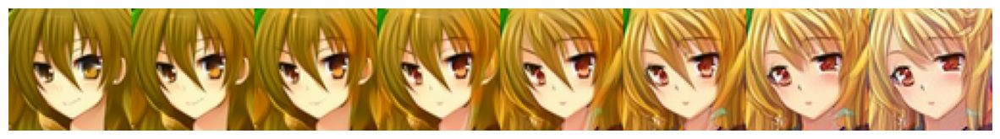

In [8]:
def slerp(a, b, s):
    om = torch.acos((a * b).sum() / (a.norm() * b.norm()))
    return (torch.sin((1 - s) * om) * a + torch.sin(s * om) * b) / torch.sin(om)
torch.manual_seed(31)
a, b = torch.randn(2, 3, 64, 64, device=dev)
ss = torch.linspace(0, 1, 32)
z = torch.stack([slerp(a, b, s) for s in ss])
x, _ = generar(z, torch.full((32,), 2, device=dev))
imgs = a_img(x)
cuadros = [(np.kron(i, np.ones((4, 4, 1))) * 255).astype(np.uint8) for i in imgs]
imageio.mimsave("resultados/interpolacion.gif", cuadros + cuadros[::-1], duration=0.08, loop=0)
plt.figure(figsize=(15, 2)); plt.imshow(grilla(imgs[::4], 8)); plt.axis("off")
plt.savefig("resultados/interpolacion.png", dpi=110); plt.show()

## 8. ¿Memoriza el dataset?

Para cada rostro generado se busca el rostro real más parecido (distancia euclidiana sobre las 63 565 imágenes).

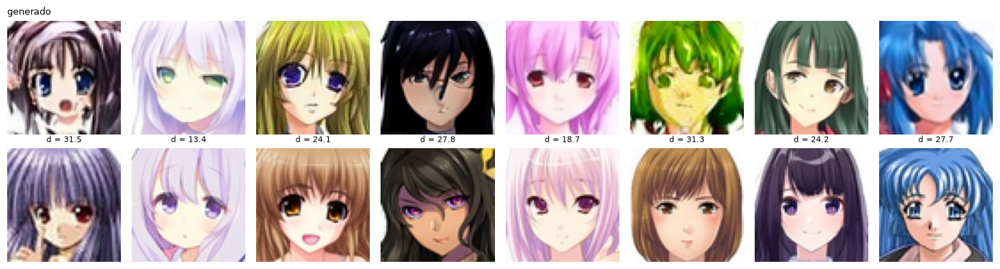

In [9]:
torch.manual_seed(41)
x, _ = generar(torch.randn(8, 3, 64, 64, device=dev), torch.randint(0, 4, (8,), device=dev))
g = a_img(x)
G = torch.from_numpy(g.reshape(8, -1)).to(dev)
mejor_d = torch.full((8,), float("inf"), device=dev); mejor_i = torch.zeros(8, dtype=torch.long, device=dev)
for k in range(0, len(d["imgs"]), 4096):
    R = torch.from_numpy(d["imgs"][k:k + 4096].reshape(-1, 64 * 64 * 3)).to(dev).float() / 255
    dist = torch.cdist(G, R)
    v, i = dist.min(1)
    m = v < mejor_d
    mejor_d[m], mejor_i[m] = v[m], i[m] + k
fig, ax = plt.subplots(2, 8, figsize=(14, 3.8))
for j in range(8):
    ax[0, j].imshow(g[j]); ax[0, j].axis("off")
    ax[1, j].imshow(d["imgs"][mejor_i[j].item()]); ax[1, j].axis("off"); ax[1, j].set_title(f"d = {mejor_d[j].item():.1f}", fontsize=8)
ax[0, 0].set_title("generado", loc="left", fontsize=9); ax[1, 0].set_ylabel("real más cercano")
plt.tight_layout(); plt.savefig("resultados/vecinos.png", dpi=110); plt.show()

## 9. Extra: llevar un rostro real a otra época

A un rostro real de 2000-2004 se le añade ruido solo hasta $t=450$ (proceso directo) y desde ahí se quita el ruido con DDIM pidiendo otra época. Se pierden los detalles finos y se conserva la forma general, así que el modelo redibuja el mismo personaje con el estilo de la época pedida. La fila *redibujado 2000-2004* es el control: mismo ruido, sin cambiar la época.

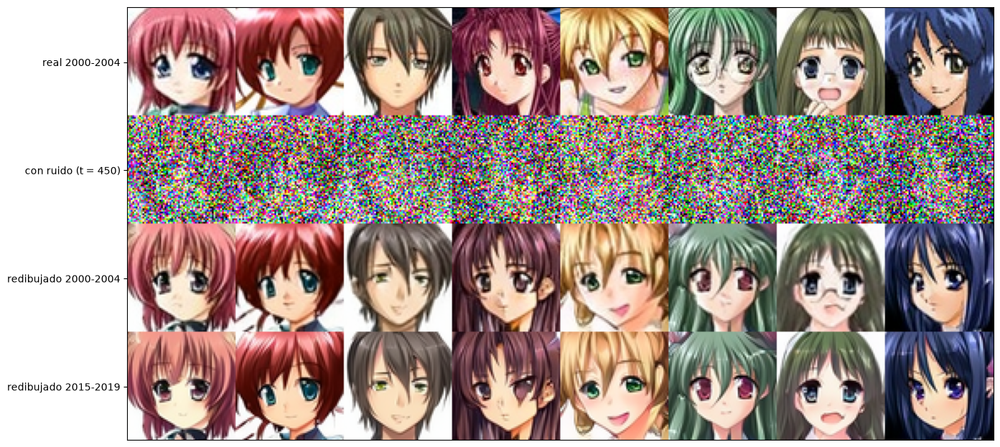

In [10]:
t0, n = 450, 8
def redibujar(idx, epoca):
    x0 = torch.from_numpy(d["imgs"][idx]).permute(0, 3, 1, 2).float().to(dev) / 127.5 - 1
    torch.manual_seed(0)
    xt = dif.ruidosa(x0, torch.full((len(idx),), t0, device=dev), torch.randn_like(x0))
    x, _ = generar(xt, torch.full((len(idx),), epoca, device=dev), guia=3.0, t_ini=t0)
    return a_img(xt), a_img(x)
idx = np.random.default_rng(1).choice(np.where(E == 0)[0], n, replace=False)
ruidosos, nuevos = redibujar(idx, 3)
_, mismos = redibujar(idx, 0)
g = np.vstack([grilla(m, n) for m in [d["imgs"][idx] / 255, ruidosos, mismos, nuevos]])
imageio.imwrite("resultados/cambio_epoca.png", (g * 255).astype(np.uint8))
plt.figure(figsize=(14, 7)); plt.imshow(g); plt.xticks([])
plt.yticks([32 + 64 * k for k in range(4)], ["real 2000-2004", f"con ruido (t = {t0})", "redibujado 2000-2004", "redibujado 2015-2019"])
plt.tight_layout(); plt.show()

In [11]:
idx = np.random.default_rng(0).choice(np.where(E == 0)[0], 512, replace=False)
filas = [("reales 2000-2004", *sat_val(d["imgs"][idx] / 255))]
for k in [0, 3]:
    r = np.concatenate([redibujar(idx[b:b + 128], k)[1] for b in range(0, 512, 128)])
    filas.append((f"redibujados {EPOCAS[k]}", *sat_val(r)))
idx3 = np.random.default_rng(3).choice(np.where(E == 3)[0], 512, replace=False)
filas.append(("reales 2015-2019", *sat_val(d["imgs"][idx3] / 255)))
print(f"{'':22s} {'sat':>6s} {'brillo':>7s}")
for f in filas:
    print(f"{f[0]:22s} {f[1]:6.3f} {f[2]:7.3f}")

                          sat  brillo
reales 2000-2004        0.310   0.691
redibujados 2000-2004   0.308   0.688
redibujados 2015-2019   0.305   0.694
reales 2015-2019        0.276   0.727


El trazo y los ojos cambian hacia el estilo pedido y el personaje se reconoce. Los detalles pequeños, como los lentes, se pueden perder. El color global casi no cambia (se hereda del rostro original): el brillo y la saturación se mueven muy poco hacia los valores de 2015-2019.

## 10. El ajuste de DDIM

DDIM estima la imagen limpia $\hat x_0$ en cada paso y la recorta a $[-1, 1]$. En `modelo.py` el ruido $\hat\epsilon$ se recalcula después de ese recorte. Con los pesos de la primera época de entrenamiento, sin ese recálculo las muestras salían como ruido (la red aún predecía mal y $\hat x_0$ se salía del rango). Aquí se comparan las dos versiones con los pesos finales y el mismo ruido inicial.

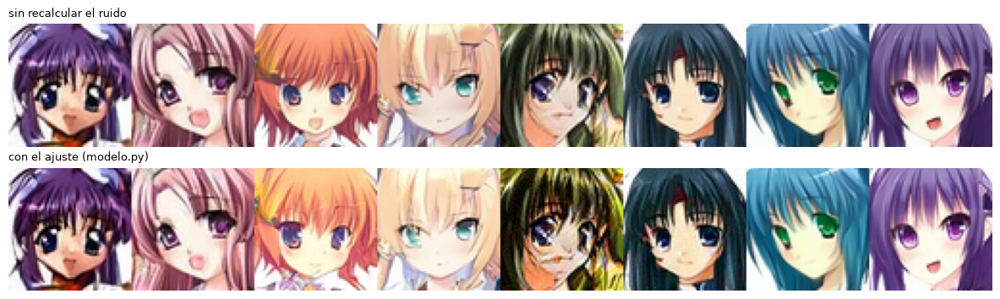

                  sat  brillo
sin ajuste      0.348   0.648
con ajuste      0.396   0.672


In [12]:
@torch.no_grad()
def ddim_sin_ajuste(x, epoca, n=50, guia=2.0):
    ts = torch.linspace(dif.T - 1, 0, n, device=dev).long()
    for i, t in enumerate(ts):
        eps = dif._eps(red, x, int(t), epoca, guia)
        ab = dif.alfa_barra[t]
        x0 = ((x - (1 - ab).sqrt() * eps) / ab.sqrt()).clamp(-1, 1)
        ab_sig = dif.alfa_barra[ts[i + 1]] if i + 1 < n else torch.tensor(1.0, device=dev)
        x = ab_sig.sqrt() * x0 + (1 - ab_sig).sqrt() * eps
    return x.clamp(-1, 1)

torch.manual_seed(5)
z = torch.randn(8, 3, 64, 64, device=dev)
e = torch.arange(4, device=dev).repeat(2)
with torch.autocast("cuda", dtype=torch.bfloat16):
    sin = ddim_sin_ajuste(z, e)
con, _ = generar(z, e)
fig, ax = plt.subplots(2, 1, figsize=(12, 3.6))
for a, x, nom in zip(ax, [sin, con], ["sin recalcular el ruido", "con el ajuste (modelo.py)"]):
    a.imshow(grilla(a_img(x), 8)); a.axis("off"); a.set_title(nom, loc="left", fontsize=9)
plt.tight_layout(); plt.savefig("resultados/ajuste_ddim.png", dpi=110); plt.show()
print(f"{'':14s} {'sat':>6s} {'brillo':>7s}")
for nom, x in [("sin ajuste", sin), ("con ajuste", con)]:
    s, v = sat_val(a_img(x)); print(f"{nom:14s} {s:6.3f} {v:7.3f}")

Con los pesos finales las dos versiones dan rostros: el ajuste fue necesario para ver muestras durante las primeras épocas de entrenamiento y hace el muestreo estable. Como efecto secundario, sube un poco el contraste y la saturación, lo que explica parte de la diferencia de saturación con los rostros reales de la sección 4.